In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from datasets import Image

In [ ]:
# Load Dataset
from datasets import load_dataset

dataset = load_dataset("hassanjbara/AI4MARS")
print(dataset)

README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

data/train-00000-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  475MB            

data/train-00000-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  476MB            

data/train-00001-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  471MB            

... (28 outputs left out)

Generating test_min1 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Generating test_min2 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Generating test_min3 split:   0%|          | 0/322 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label_mask', 'rover_mask', 'range_mask', 'has_masks', 'has_labels'],
        num_rows: 18130
    })
    test_min1: Dataset({
        features: ['image', 'label_mask', 'rover_mask', 'range_mask', 'has_masks', 'has_labels'],
        num_rows: 322
    })
    test_min2: Dataset({
        features: ['image', 'label_mask', 'rover_mask', 'range_mask', 'has_masks', 'has_labels'],
        num_rows: 322
    })
    test_min3: Dataset({
        features: ['image', 'label_mask', 'rover_mask', 'range_mask', 'has_masks', 'has_labels'],
        num_rows: 322
    })
})


In [10]:
print("DATASET OVERVIEW")
print("=" * 50)

for split, data in dataset.items():
    print(f"\n{split.upper()}")
    print(f"Samples: {len(data)}")
    print(f"Features: {data.features}")

DATASET OVERVIEW

TRAIN
Samples: 18130
Features: {'image': Image(mode=None, decode=True), 'label_mask': Image(mode=None, decode=True), 'rover_mask': Image(mode=None, decode=True), 'range_mask': Image(mode=None, decode=True), 'has_masks': Value('bool'), 'has_labels': Value('bool')}

TEST_MIN1
Samples: 322
Features: {'image': Image(mode=None, decode=True), 'label_mask': Image(mode=None, decode=True), 'rover_mask': Image(mode=None, decode=True), 'range_mask': Image(mode=None, decode=True), 'has_masks': Value('bool'), 'has_labels': Value('bool')}

TEST_MIN2
Samples: 322
Features: {'image': Image(mode=None, decode=True), 'label_mask': Image(mode=None, decode=True), 'rover_mask': Image(mode=None, decode=True), 'range_mask': Image(mode=None, decode=True), 'has_masks': Value('bool'), 'has_labels': Value('bool')}

TEST_MIN3
Samples: 322
Features: {'image': Image(mode=None, decode=True), 'label_mask': Image(mode=None, decode=True), 'rover_mask': Image(mode=None, decode=True), 'range_mask': Image

In [11]:
train_df = pd.DataFrame({
    "has_masks": dataset["train"]["has_masks"],
    "has_labels": dataset["train"]["has_labels"]
})

print("ANNOTATION DISTRIBUTION")
print("=" * 50)

print(train_df.value_counts().sort_index())
print("\nPercentage distribution:")
print((train_df.value_counts(normalize=True) * 100).round(2))

ANNOTATION DISTRIBUTION
has_masks  has_labels
False      False            33
           True              1
True       False          2033
           True          16063
Name: count, dtype: int64

Percentage distribution:
has_masks  has_labels
True       True          88.60
           False         11.21
False      False          0.18
           True           0.01
Name: proportion, dtype: float64


In [ ]:
# Sample Image
train_data = dataset["train"]

labeled_indices = [
    i for i, value in enumerate(train_data["has_labels"])
    if value
]

unlabeled_indices = [
    i for i, value in enumerate(train_data["has_labels"])
    if not value
]

print("Labeled samples:", len(labeled_indices))
print("Unlabeled samples:", len(unlabeled_indices))

labeled_sample = train_data[labeled_indices[0]]
unlabeled_sample = train_data[unlabeled_indices[0]]

print("\nLabeled sample:")
print("Image:", labeled_sample["image"])
print("Label mask:", labeled_sample["label_mask"])
print("Has masks:", labeled_sample["has_masks"])
print("Has labels:", labeled_sample["has_labels"])

print("\nUnlabeled sample:")
print("Image:", unlabeled_sample["image"])
print("Label mask:", unlabeled_sample["label_mask"])
print("Has masks:", unlabeled_sample["has_masks"])
print("Has labels:", unlabeled_sample["has_labels"])

Labeled samples: 16064
Unlabeled samples: 2066

Labeled sample:
Image: <PIL.JpegImagePlugin.JpegImageFile image mode=L size=1024x1024 at 0x13A5CC950>
Label mask: <PIL.PngImagePlugin.PngImageFile image mode=L size=1024x1024 at 0x11937C850>
Has masks: True
Has labels: True

Unlabeled sample:
Image: <PIL.JpegImagePlugin.JpegImageFile image mode=L size=1024x1024 at 0x13A52DDD0>
Label mask: None
Has masks: True
Has labels: False


In [ ]:
# Image dimensions and modes
image_modes = Counter()
image_sizes = Counter()

mask_modes = Counter()
mask_sizes = Counter()

for i in range(min(200, len(train_data))):
    sample = train_data[i]

    if sample["image"] is not None:
        image_modes[sample["image"].mode] += 1
        image_sizes[sample["image"].size] += 1

    for key in ["label_mask", "rover_mask", "range_mask"]:
        mask = sample[key]

        if mask is not None:
            mask_modes[mask.mode] += 1
            mask_sizes[mask.size] += 1

print("IMAGE MODES:", image_modes)
print("IMAGE SIZES:", image_sizes)

print("\nMASK MODES:", mask_modes)
print("MASK SIZES:", mask_sizes)

IMAGE MODES: Counter({'L': 200})
IMAGE SIZES: Counter({(1024, 1024): 200})

MASK MODES: Counter({'L': 541})
MASK SIZES: Counter({(1024, 1024): 541})


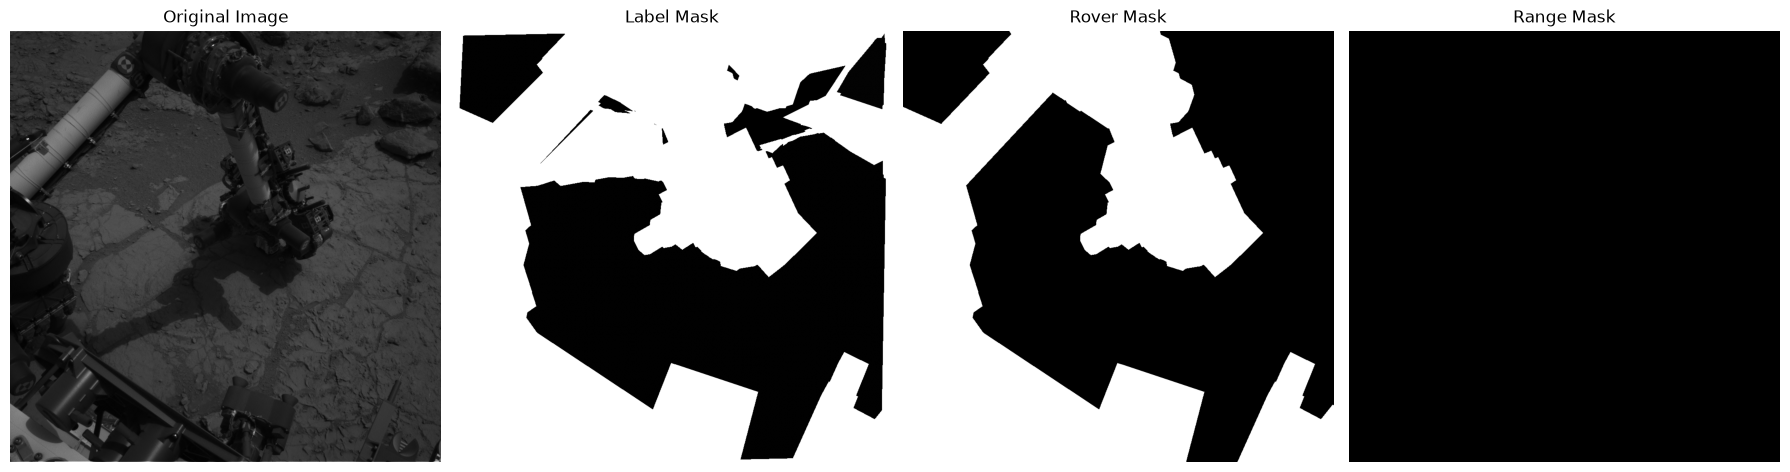

In [ ]:
# Visualize Sample
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

sample = labeled_sample

axes[0].imshow(sample["image"], cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(sample["label_mask"], cmap="gray")
axes[1].set_title("Label Mask")

axes[2].imshow(sample["rover_mask"], cmap="gray")
axes[2].set_title("Rover Mask")

axes[3].imshow(sample["range_mask"], cmap="gray")
axes[3].set_title("Range Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Mask's Pixels
mask_types = ["label_mask", "rover_mask", "range_mask"]

for mask_type in mask_types:
    print(f"\n{mask_type.upper()}")
    print("-" * 40)

    sample_values = []

    for idx in labeled_indices[:100]:
        mask = train_data[idx][mask_type]

        if mask is not None:
            values = np.unique(np.array(mask))
            sample_values.extend(values.tolist())

    unique_values = sorted(set(sample_values))

    print("Unique pixel values:", unique_values)
    print("Number of unique values:", len(unique_values))


LABEL_MASK
----------------------------------------
Unique pixel values: [0, 1, 2, 3, 255]
Number of unique values: 5

ROVER_MASK
----------------------------------------
Unique pixel values: [0, 1]
Number of unique values: 2

RANGE_MASK
----------------------------------------
Unique pixel values: [0, 1]
Number of unique values: 2


In [20]:
# Mask pixel distribution
pixel_counts = Counter()

for idx in labeled_indices[:100]:
    mask = train_data[idx]["label_mask"]

    if mask is not None:
        values, counts = np.unique(
            np.array(mask),
            return_counts=True
        )
        for value, count in zip(values, counts):
            pixel_counts[int(value)] += int(count)

print("LABEL MASK PIXEL DISTRIBUTION")
print("=" * 50)

for value, count in sorted(pixel_counts.items()):
    print(f"Pixel value {value}: {count:,} pixels")

LABEL MASK PIXEL DISTRIBUTION
Pixel value 0: 21,128,115 pixels
Pixel value 1: 30,323,671 pixels
Pixel value 2: 6,671,689 pixels
Pixel value 3: 917,845 pixels
Pixel value 255: 45,816,280 pixels


In [25]:
# Disable image decoding for label_mask
raw_data = train_data.cast_column(
    "label_mask",
    Image(decode=False)
)

# Retrieve annotation metadata
label_masks = raw_data["label_mask"]
has_labels = raw_data["has_labels"]

inconsistencies = []

for i, (mask, label) in enumerate(zip(label_masks, has_labels)):

    actual_label = mask is not None

    if actual_label != label:
        inconsistencies.append(i)

print("Annotation inconsistencies:", len(inconsistencies))
print("Inconsistent indices:", inconsistencies[:20])

Annotation inconsistencies: 0
Inconsistent indices: []


In [ ]:
# Test Splits
for split in ["test_min1", "test_min2", "test_min3"]:
    data = dataset[split]

    df = pd.DataFrame({
        "has_masks": data["has_masks"],
        "has_labels": data["has_labels"]
    })

    print(f"\n{split.upper()}")
    print("-" * 40)
    print(df.value_counts().sort_index())


TEST_MIN1
----------------------------------------
has_masks  has_labels
True       True          322
Name: count, dtype: int64

TEST_MIN2
----------------------------------------
has_masks  has_labels
True       True          322
Name: count, dtype: int64

TEST_MIN3
----------------------------------------
has_masks  has_labels
True       True          322
Name: count, dtype: int64


In [30]:
print("=" * 55)
print("AI4MARS DATASET EXPLORATION SUMMARY")
print("=" * 55)

print("\nDATASET SPLITS")

for split, data in dataset.items():
    print(f"{split}: {len(data):,} samples")

print("\nTRAINING ANNOTATIONS")

print("Total samples:", len(train_data))
print("Labeled samples:", len(labeled_indices))
print("Unlabeled samples:", len(unlabeled_indices))

print("\nMASK AVAILABILITY")

for mask_type in ["label_mask", "rover_mask", "range_mask"]:

    raw_column = train_data.cast_column(
        mask_type, Image(decode=False)
    )[mask_type]

    available = sum(item is not None for item in raw_column)

    print(f"{mask_type}: {available:,}/{len(train_data):,}")

print("\nANNOTATION INCONSISTENCIES:", len(inconsistencies))

AI4MARS DATASET EXPLORATION SUMMARY

DATASET SPLITS
train: 18,130 samples
test_min1: 322 samples
test_min2: 322 samples
test_min3: 322 samples

TRAINING ANNOTATIONS
Total samples: 18130
Labeled samples: 16064
Unlabeled samples: 2066

MASK AVAILABILITY
label_mask: 16,064/18,130
rover_mask: 18,097/18,130
range_mask: 18,096/18,130

ANNOTATION INCONSISTENCIES: 0
